<div style="padding:30px 34px;border-radius:18px;background:linear-gradient(135deg,#102A43 0%,#136F63 100%);color:white;margin-bottom:18px">
  <div style="font-size:13px;letter-spacing:.12em;text-transform:uppercase;opacity:.82">Análisis y Exploración de Datos · ISFT N.° 189 · Luján</div>
  <h1 style="font-size:34px;margin:9px 0 5px 0;color:white">Análisis Exploratorio de Datos (EDA)</h1>
  <div style="font-size:21px;font-weight:500">Reportes auditoría de calidad del catálogo Línea 144</div>
  <div style="font-size:15px;margin-top:14px;opacity:.9">Fuente: DataSet <a href="https://www.kaggle.com/datasets/aracelifernandez/base-de-datos-linea-144-argentina"> Línea 144 </a> · Período 2020-2023 · Python + pandas + seaborn</div>
</div>

## Antes de empezar · Contexto, fuente y alcance

Usaremos el dataset: **Base de datos Linea 144 Argentina**.

Comunicaciones recibidas por la Línea 144, la cuál brinda atención a mujeres y LGBTI+ en situación de violencia de género.

- [Origen del Dataset](https://www.kaggle.com/datasets/aracelifernandez/base-de-datos-linea-144-argentina)

# Codificación del achivo csv

* Abrimos el archivo de datos en formato 'utf-8' e intentamos leer el contenido capturanddo la excepción en caso de error.

In [3]:
try:
    f = open('Base.csv', 'r', encoding='utf-8')
    f.read()  # Intenta leer todo el contenido
    print("Formato utf-8 correcto")
except Exception as e:
    print(f"Error de codificación utf-8: {e}")
finally:
   f.close()

Error de codificación utf-8: 'utf-8' codec can't decode byte 0xf1 in position 1: invalid continuation byte


* se detectó error de decodifición.
* Asumimos que puede estar codificado en cp1252.

*`cp1252` (Windows-1252) es un superconjunto de `latin-1`. Mapea los mismos caracteres en español, pero además incluye caracteres corporativos esenciales que `latin-1` no reconoce correctamente:*

In [4]:
try:
    f = open('Base.csv', 'r', encoding='cp1252')
    contenido = f.read()  # Intenta leer todo el contenido
    print("Formato cp1252 sin error")
except Exception as e:
    print(f"Error de codificación utf-8: {e}")
finally:
   f.close()

Formato cp1252 sin error


* La lectura no generó errores, creamos un nuevo archivo (base_utf8.csv) codificado en formato utf-8, conservando el archivo raw (Base.csv).

In [5]:
try:
    f = open('Base.csv', 'r', encoding='cp1252')
    contenido = f.read()
    d = open('base_utf8.csv', 'w', encoding='utf-8')
    d.write(contenido)
    print('Archivo generado base_utf8.csv generado correctamente')
except UnicodeDecodeError:
    print('Error al convertir archivo')
finally:
   f.close()
   d.close()

Archivo generado base_utf8.csv generado correctamente


## Diccionario de Datos
- **Año:** Registro del año en que se recibió el reporte.
- **Fecha:** Registro del día, mes y año en que se recibió el reporte.
- **prov_persona_en_situacion_violencia:** Provincia de residencia de la persona afectada.
- **genero_persona_en_situacion_de_violencia:** Identidad de género de la persona afectada (Mujer, Varón, LGTBI+, etc.).
- **edad_persona_en_situacion_de_violencia:** Años de la persona afectada.
- **pais_nacimiento_persona_en_situacion_de_violencia:** País de nacimiento de la persona afectada.
- **tipo_de_violencia_fisica:** Indica si existió agresión sobre el cuerpo (golpe, empujon, tiron del pelo, etc.).
- **tipo_de_violencia_psicologica:** Indica si hubo maltrato emocional, verbal, amenazas, humillaciones, etc.
- **tipo_de_violencia_sexual:** Indica si hubo sometimiento o agresión de caracter sexual.
- **tipo_de_violencia_economica_y_patrimonial:** Indica si hubo robo, destrucción de bienes personales, privación o control extorsivo de dinero o recursos.
- **tipo_de_violencia_simbolica:** Indica si hubo imposición de ideas, mensajes, imágenes que hacen ver normal los prejuicios y la desigualdad hacía las mujeres.
- **tipo_de_violencia_domestica:** Indica si la agresión fue ejercida por un integrante del grupo familiar en el ámbito del hogar.
- **modalidad_de_violencia_institucional:** Indica si las acciones u omisiones discriminatorias provinieron de funcionarios o instituciones públicas.
- **modalidad_de_violencia_laboral:** Indica si la discriminación o el acaso ocurrieron dentro del ámbito de trabajo.
- **modalidad_violencia_contra_libertad_reproductiva:** Indica si impidió el libre derecho a decidir el número de embarazos o el intervalo entre ellos.
- **modalidad_de_violencia_obstetrica:** Indica tratos deshumanizados o abuso médico durante los procesos reproductivos.
- **modalidad_de_violencia_mediatica:** Indica si hubo publicaciones, difusiones o mensajes a través de cualquier medio de comunicación que promueva la explotación de las mujeres que difamen, discriminen o atenten contra su dignidad.
- **modalidad_de_violencia_otras:** Indica e identifica si hubo otro tipo de violencia que no encuadre de forma directa en las clasificaciones predefinidas por la ley de protección integral, sirviendo como variable residual.
- **vinculo_con_la_persona_agresora:** Relación de la víctima con el agresor/a (Ex pajera, Pareja, Familiar, etc.).
- **genero_de_la_persona_agresora:** Identidad de género registrara de quien ejerce la agresión.
- **poblacion_provincia:** Cantidad de población por provincia para facilitad el cálculo de tasas.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import missingno as msno

In [7]:
df = pd.read_csv('base_utf8.csv', encoding='utf-8')

def sample_values(series, n=18):
    values = series.dropna().astype(str).drop_duplicates().head(n).tolist()
    return " · ".join(values)

structural_profile = pd.DataFrame({
    "columna": df.count(),
    "dtype_pandas": df.dtypes.astype(str).values,
    "ejemplos": [sample_values(df[c]) for c in df.columns],
})

display(structural_profile)

,columna,dtype_pandas,ejemplos
Año,89540,int64,2023 · 2022 · 2021 · 2020
Fecha,89540,object,1/1/2023 · 1/2/2023 · 1/3/2023 · 1/4/2023 · 1/...
prov_persona_en_situacion_violencia,89540,object,Buenos Aires · Entre Ríos · Mendoza · Tucumán ...
genero_persona_en_situacion_de_violencia,87636,object,Mujer · Transgenero · Varon · Varon Trans · Mu...
edad_persona_en_situacion_de_violencia,72262,float64,19.0 · 46.0 · 28.0 · 34.0 · 38.0 · 57.0 · 39.0...
pais_nacimiento_persona_en_situacion_de_violencia,59259,object,Argentina · Paraguaya · Colombiana · Boliviana...
tipo_de_violencia_fisica,89540,object,Si · No
tipo_de_violencia_psicologica,89540,object,Si · No
tipo_de_violencia_sexual,89540,object,No · Si · SI
tipo_de_violencia_economica_y_patrimonial,89540,object,No · Si


- Hay un total de 89540 registros con 21 campos.
- Un atributo es de tipo decimal (*float64* -> *edad_persona_en_situacion_de_violencia*).
- Un atributo es de tipo numérico (*int64* -> *Año*).
- El resto de atributos son de tipo *object*.
- Columna Año presenta valores numéricos dentro del rango correcto, 2020 a 2023 en formato numérico.
- Las columnas con valores Si/No presentan problemas a solucionar (por ejemplo: No · Si · SI). 
- Hay unos cuantos atributos que no tienen la totalidad de instancias.

## Análisis Descriptivo de los datos

In [26]:
df.describe(include='number').round(3)

,Año,edad_persona_en_situacion_de_violencia
count,89540.000,72262.000
mean,2021.165,35.688
std,1.012,12.597
min,2020.000,1.000
25%,2020.000,27.000
50%,2021.000,34.000
75%,2022.000,42.000
max,2023.000,127.000


- No se ve un fenómeno en especial dentro de **Año**
- En la edad de la victima se encuentra que el valor máximo encontrado es *127 años*, aunque es posible vivir hasta esa edad, puede ser algún error de tipeo.
- Otro valor atípico sería la edad mínima de *1 año*, y dado que el dataset de reportes de la línea 144 es sobre reportes, registrar que un bebe es la persona afectada, podría ser un error de registro.
- También dentro de la misma variable se encuentra que hay reportes que no anotaron la edad de la persona, puede ser por la victima que no quiso dar esa información, es un registro censurado o eliminado a propósito, etc.

In [9]:
df.describe(include='object')

,Fecha,prov_persona_en_situacion_violencia,genero_persona_en_situacion_de_violencia,pais_nacimiento_persona_en_situacion_de_violencia,tipo_de_violencia_fisica,tipo_de_violencia_psicologica,tipo_de_violencia_sexual,tipo_de_violencia_economica_y_patrimonial,tipo_de_violencia_simbolica,tipo_de_violencia_domestica,modalidad_de_violencia_institucional,modalidad_de_violencia_laboral,modalidad_violencia_contra_libertad_reproductiva,modalidad_de_violencia_obstetrica,modalidad_de_violencia_mediatica,modalidad_de_violencia_otras,vinculo_con_la_persona_agresora,genero_de_la_persona_agresora,poblacion_provincia
count,89540,89540,87636,59259,89540,89540,89540,89540,89540,89540,89540,89540,89540,89540,89540,89540,86145,80327,88228
unique,1277,27,12,45,2,2,3,2,3,2,3,3,3,3,2,2,7,11,24
top,8/9/2020,Buenos Aires,Mujer,Argentina,Si,Si,No,No,No,Si,No,No,No,No,No,No,Ex pareja,Varon,17569053
freq,138,48565,86883,52942,58964,84992,77301,53609,58958,81334,88236,88289,89140,89455,89487,87433,42247,79025,48565


- En algunas columnas (como ```tipo_de_violencia_sexual```, ```tipo_de_violencia_simbolica```, ```modalidad_de_violencia_laboral```, entre otras), *df.describe()* muestra 3 valores únicos en lugar de 2, ya que en estas variables categóricas deben tener *"Sí"* o *"No"*, esto quiere decir que hay inconsistencias en la carga de datos.

- En la columna ```genero_persona_en_situacion_de_violencia``` tiene 12 valores únicos, mientras que ```genero_de_la_persona_agresora``` contiene 11 valores únicos. Es probable que existan categorías duplicadas, mal escritas, incoherencias, etc.

- La columna ```pais_nacimiento_persona_en_situacion_de_violencia``` tiene 59259 registros, y la totalidad es de 89540, significa que un 34% de los datos están vacíos (nulos), representando una perdida importante de información.

- El atributo ```Fecha``` esta guardado como tipo *objeto* en lugar de un tipo *datetime*, impidiendo hacer análisis de tiempo. Lo mismo ```poblacion_provincia``` es de tipo *objeto* en lugar de tipo *float64* (para que admita nulos).






## Preparación de los Datos

### Chequeo de valores `poblacion_provincia`

In [10]:
# Intentamos convertir a número. Los errores se convierten en NaN (nulos)
conversion_temporal = pd.to_numeric(df["poblacion_provincia"], errors="coerce")

# Filtramos el DataFrame original donde la conversión falló y el valor original NO era nulo
valores_incorrectos = df[ conversion_temporal.isna() & df["poblacion_provincia"].notna()]

# Mostrar los valores únicos que están causando el problema
print("Valores incorrectos detectados:", len(valores_incorrectos))
print(valores_incorrectos["poblacion_provincia"].unique())

# Contar cuántas veces aparece cada valor problemático
print(valores_incorrectos["poblacion_provincia"].value_counts())


Valores incorrectos detectados: 3411
['3,978,984.00' '1,142,963.00']
poblacion_provincia
3,978,984.00    2610
1,142,963.00     801
Name: count, dtype: int64


* Solución posible:

In [11]:
formateados = ( df["poblacion_provincia"].str.replace(",", "", regex=False).str.replace(r"\.\d+", "", regex=True) )

conversion_temporal = pd.to_numeric(formateados, errors="coerce")

valores_incorrectos = df[ conversion_temporal.isna() & formateados.notna()]

print("Valores incorrectos detectados:", len(valores_incorrectos))
df['poblacion_provincia'].count()

Valores incorrectos detectados: 0


np.int64(88228)

### Chequeo de formato del campo Fecha (Object) para convertir a datetime

* Visualmente los posibles formatos pueden ser día/mes/año o mes/día/año

* Se prueba formato día/mes/año

In [12]:
fechas = pd.to_datetime(df['Fecha'], format='%d/%m/%Y', errors='coerce')

exitosas = fechas.notna().sum()
total_filas = len(df)

print(f"Pandas logró detectar y convertir {exitosas} de {total_filas} filas.")

Pandas logró detectar y convertir 35790 de 89540 filas.


* No se pudieron convertir 35790 valores de 89540 (La regla de la ambigüedad) 

* Probar formato mes/día/año

In [13]:
fechas = pd.to_datetime(df['Fecha'], format='%m/%d/%Y', errors='coerce')

exitosas = fechas.notna().sum()
total_filas = len(df)

print(f"Pandas logró detectar y convertir {exitosas} de {total_filas} filas.")

Pandas logró detectar y convertir 89540 de 89540 filas.


* Conversión perfecta (89540 de 89540) Se detecta formato EEUU mes/día/año

In [14]:
df['Fecha'].describe()

count        89540
unique        1277
top       8/9/2020
freq           138
Name: Fecha, dtype: object

Se realizo una pequeña busqueda sobre la cantidad de días que pasaron entre el **2020-01-01** hasta el **2023-06-30** y da exactamente **1277 días**, es decir, todo reporte realizado a la línea 144, esta guardado en este dataset.

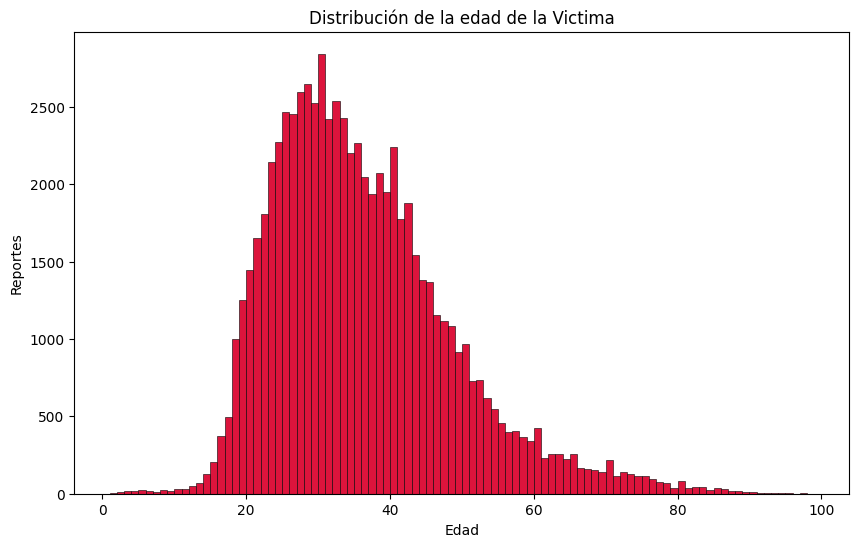

In [15]:
# Histograma de la variable numérica 'edad' para analizar la distribució.
plt.figure(figsize=(10, 6))
plt.hist(df['edad_persona_en_situacion_de_violencia'], bins=range(1, 100), color='crimson', edgecolor='black', linewidth=0.4)
plt.title('Distribución de la edad de la Victima')
plt.xlabel('Edad')
plt.ylabel('Reportes')
plt.show()

In [16]:
# Mostrar cuántos registros faltan en Edad
print(f"Valores nulos en Edad: {df['edad_persona_en_situacion_de_violencia'].isnull().sum()}")

# Tabla para mostrar exactamente la cantidad de reportes que hubo por edad.
frecuencia_edades = pd.DataFrame(df['edad_persona_en_situacion_de_violencia'].value_counts()).reset_index()

# Renombrado de columnas y ordenado de manera ascendente.
frecuencia_edades.columns = ['Edad', 'Frecuencia']
frecuencia_edades = frecuencia_edades.sort_values(by='Edad')

pd.set_option('display.max_rows', 100) # Permite mostrar las 100 filas
frecuencia_edades

Valores nulos en Edad: 17278


,Edad,Frecuencia
89,1.0,6
88,2.0,9
84,3.0,15
80,4.0,20
77,5.0,22
82,6.0,17
87,7.0,9
78,8.0,22
81,9.0,18
75,10.0,31


La mayor cantidad de reportes hechos son entre los 20 a 40 años como se ve en el histograma, el mínimo es 1 y el máximo es 127, pero como se sabe, la edad donde hubo más reportes es de 30 años.

Los reportes de menores de 10 años pudieron ser error de tipado o fueron reportados por otra persona, mientras que el registro de 127 años podrá ser un error de tipado aunque alguién con esa edad es posible.

### Análisis Exploratorio de las Variables Categóricas

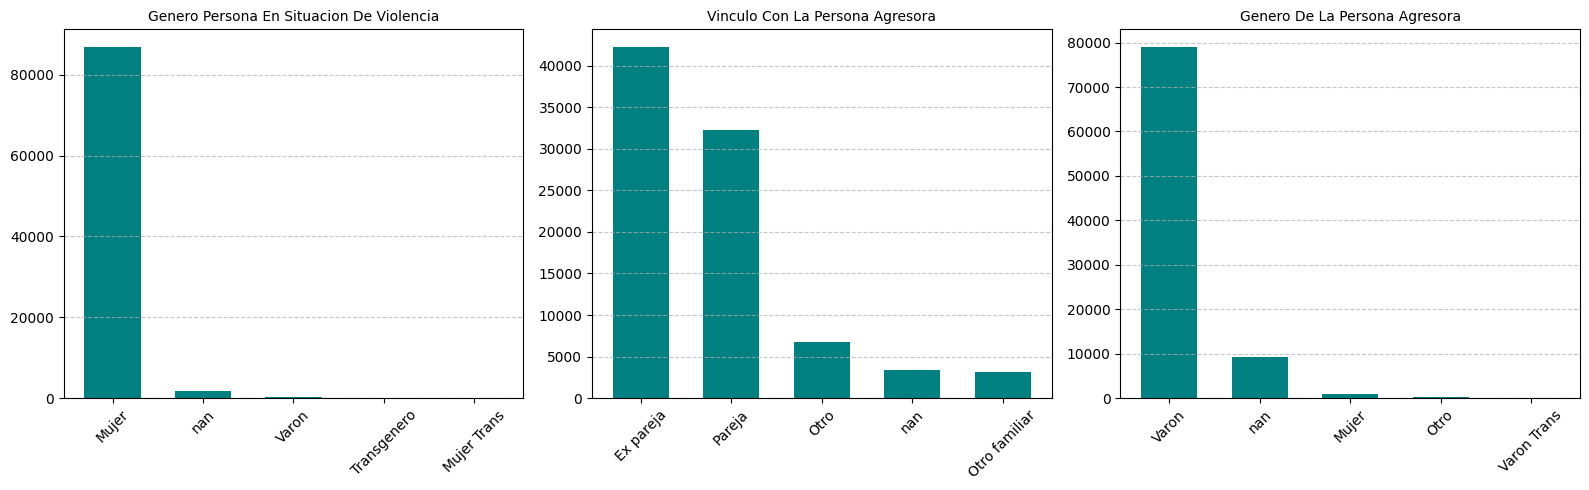

In [17]:
# Análisis con histograma de las variables categóricas
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

categoricas = ["genero_persona_en_situacion_de_violencia",
               "vinculo_con_la_persona_agresora",
               "genero_de_la_persona_agresora"
]

for ax, c in zip(axs, categoricas):
    # Se obtienen los 5 valores más comunes para que el gráfico sea mas legible
    vc = df[c].value_counts(dropna=False).head(5)

    ax.bar(vc.index.astype(str), vc.values, color='teal', width=0.62)
    ax.set_title(c.replace('_', ' ').title(), fontsize=10)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

- **Género Persona en Situación de Violencia:** Se puede ver como casi la totalidad de los reportes por violencia fueron hechos por *Mujeres*, mientras que otros dos valores más pequeños no se encuentra registro (podrá ser algún error de tipeo, o depende algo dentro del propio valor), o muy pocos *Hombres* también reportaron (podrá ser para pedir asistencia o denuncia por una mujer que conoce o por otra razón en particular).

- **Vinculo con la Persona Agresora:** El vinculo más común entre la victima y el agresor son sus *Ex Parejas*, o  la misma *Pareja*, se puede ver como también hay registros que no están en el dataset, lo llamativo es que como tercer puesto sea *Otro*, luego se investigara al respecto, pero podrá ser algo del dato que no se encuentre disponible.

- **Género de la Persona Agresora:** El género más común en agredir a la Mujer fue el *Hombre*, aunque también hubieron reportes donde el género no se encuentra en el atributo, podrá ser algo del mismo dato que no se tiene información o en el reporte la victima no quiso dar esa información o está censurada.

In [18]:
# Exploración de los tipos de violencias
# Separación de las columnas según el tipo de violencia
columnas_violencia = ['tipo_de_violencia_fisica', 'tipo_de_violencia_psicologica',
                      'tipo_de_violencia_sexual', 'tipo_de_violencia_economica_y_patrimonial',
                      'tipo_de_violencia_simbolica', 'tipo_de_violencia_domestica'
]

# Distribución de las Variables de Violencia (Sí/No)
print("\nANÁLISIS DE TIPOS DE VIOLENCIA (Valores únicos registrados)")
for col in columnas_violencia:
    print(df[col].value_counts(dropna=False))
    print(f"Nulos: {df[col].isnull().sum()}\n")


ANÁLISIS DE TIPOS DE VIOLENCIA (Valores únicos registrados)
tipo_de_violencia_fisica
Si    58964
No    30576
Name: count, dtype: int64
Nulos: 0

tipo_de_violencia_psicologica
Si    84992
No     4548
Name: count, dtype: int64
Nulos: 0

tipo_de_violencia_sexual
No    77301
Si    12238
SI        1
Name: count, dtype: int64
Nulos: 0

tipo_de_violencia_economica_y_patrimonial
No    53609
Si    35931
Name: count, dtype: int64
Nulos: 0

tipo_de_violencia_simbolica
No    58958
Si    30155
SI      427
Name: count, dtype: int64
Nulos: 0

tipo_de_violencia_domestica
Si    81334
No     8206
Name: count, dtype: int64
Nulos: 0



No hay nulos en las variables, pero, se puede ver como hay valores distintos a *Si* y *No* en los distintos tipos de violencia, generando coherencia, por el momento solo **SI** es el tercer valor que debe ser filtrado.

In [19]:
# Se calcula la cantidad de casos 'Si' (normalizando a mayúsculas para evitar inconsistencias).
conteo_violencia = {}

for col in columnas_violencia:
    # Se filtra las respuestás a 'Si'
    cantidad_si = df[col].astype(str).str.upper().eq('SI').sum()

    # Se reemplaza el nombre de la columna para una mejor lectura en la tabla
    nombre_limpio = col.replace('tipo_de_violencia_', '').replace('_', ' ').capitalize()
    conteo_violencia[nombre_limpio] = cantidad_si

# Se crea un DataFrame ordenado de manera descendente
df_conteo = pd.DataFrame(list(conteo_violencia.items()), columns=['Tipo de Violencia', 'Cantidad de Reportes'])
df_conteo = df_conteo.sort_values(by='Cantidad de Reportes', ascending=False)

print("Tabla de Frecuencias:")
df_conteo

Tabla de Frecuencias:


,Tipo de Violencia,Cantidad de Reportes
1,Psicologica,84992
5,Domestica,81334
0,Fisica,58964
3,Economica y patrimonial,35931
4,Simbolica,30582
2,Sexual,12239


Luego de acomodar, se obtiene que hay más tipos de violencia:
1. Psicologica con 84992 confirmados
2. Domestica con 81334 confirmados
3. Fisica con 58964 confirmados

### Exploración de los tipos de Modalidad de Violencia

In [20]:
# Separación de las columnas según el tipo de modalidad
columnas_modalidad = ['modalidad_de_violencia_institucional',
       'modalidad_de_violencia_laboral',
       'modalidad_violencia_contra_libertad_reproductiva',
       'modalidad_de_violencia_obstetrica', 'modalidad_de_violencia_mediatica',
       'modalidad_de_violencia_otras'
]

# Distribución de las Variables de Modalidad de Violencia (Sí/No)
print("\nANÁLISIS DE TIPOS DE MODALIDAD DE VIOLENCIA (Valores únicos registrados)")
for col in columnas_modalidad:
    print(df[col].value_counts(dropna=False))
    print(f"Nulos: {df[col].isnull().sum()}\n")


ANÁLISIS DE TIPOS DE MODALIDAD DE VIOLENCIA (Valores únicos registrados)
modalidad_de_violencia_institucional
No    88236
Si     1288
SI       16
Name: count, dtype: int64
Nulos: 0

modalidad_de_violencia_laboral
No    88289
Si     1250
SI        1
Name: count, dtype: int64
Nulos: 0

modalidad_violencia_contra_libertad_reproductiva
No    89140
Si      395
SI        5
Name: count, dtype: int64
Nulos: 0

modalidad_de_violencia_obstetrica
No    89455
Si       84
SI        1
Name: count, dtype: int64
Nulos: 0

modalidad_de_violencia_mediatica
No    89487
Si       53
Name: count, dtype: int64
Nulos: 0

modalidad_de_violencia_otras
No    87433
Si     2107
Name: count, dtype: int64
Nulos: 0



No hay nulos en las variables, pero, se puede ver como hay valores distintos a *Si* y *No* en los distintos tipos de modalidad de violencia, generando coherencia, por el momento solo **SI** es el tercer valor que debe ser filtrado.

### Exploración de Frecuencia en los Tipos de Violencia

In [21]:
# Se calcula la cantidad de casos 'Si' (normalizando a mayúsculas para evitar inconsistencias).
conteo_violencia = {}

for col in columnas_modalidad:
    # Se filtra las respuestás a 'Si'
    cantidad_si = df[col].astype(str).str.upper().eq('SI').sum()

    # Se reemplaza el nombre de la columna para una mejor lectura en la tabla
    nombre_limpio = col.replace('modalidad_de_violencia_', '').replace('_', ' ').capitalize()
    conteo_violencia[nombre_limpio] = cantidad_si

# Se crea un DataFrame ordenado de manera descendente
df_conteo = pd.DataFrame(list(conteo_violencia.items()), columns=['Tipo de Violencia', 'Cantidad de Reportes'])
df_conteo = df_conteo.sort_values(by='Cantidad de Reportes', ascending=False)

print("Tabla de Frecuencias:")
df_conteo

Tabla de Frecuencias:


,Tipo de Violencia,Cantidad de Reportes
5,Otras,2107
0,Institucional,1304
1,Laboral,1251
2,Modalidad violencia contra libertad reproductiva,400
3,Obstetrica,85
4,Mediatica,53


Luego de acomodar, se obtiene que hay más modalidad de violencia en:
1. Otras con 2107 confirmados
2. Institucional con 1304 confirmados
3. Laboral con 1251 confirmados

Habrá que realizar un análisis en los casos de tipo de violencia *Otras* para ofrecer una mejor conclusión al respecto.

In [22]:
columnas_categoricas = ['prov_persona_en_situacion_violencia',
                        'genero_persona_en_situacion_de_violencia',
                        'vinculo_con_la_persona_agresora',
                        'genero_de_la_persona_agresora'
]

# Categorías generales
print("\n----- CATEGORÍAS POR VARIABLE -----")
for col in columnas_categoricas:
    print(df[col].value_counts(dropna=False))
    print(f"Nulos: {df[col].isnull().sum()}\n")


----- CATEGORÍAS POR VARIABLE -----
prov_persona_en_situacion_violencia
Buenos Aires                                             48565
Ciudad Autónoma de Buenos Aires                          17397
Santa Fe                                                  3785
Tucumán                                                   3224
Mendoza                                                   3132
Córdoba                                                   2610
Sin datos                                                 1287
Jujuy                                                     1252
Salta                                                     1232
Chaco                                                      801
San Luis                                                   733
San Juan                                                   654
Entre Ríos                                                 631
Neuquén                                                    613
Misiones                                     

#### **Provincia de la Victima que realizo el Reporte:**
- No hay existencia de nulos en el atributo, aunque hay **25** registros `Sin Datos` y en otra variable casi igual hay **1287** `Sin datos`, probablemente la victima no quiso dar esa información o hubo algún error.
- El pais con menos reportes es Santiago del Estero con **68** registros.
- La provincia de Buenos Aires es donde más reportes hubo entre 2020 y 2023 (**48565**), luego le sigue CABA con **17397** reportes, después Santa Fe con **3785**, y comp cuarto Tucumán con **3224**.
- Aun así, CABA es parte de la provincia de Buenos Aires, así que la suma total de reportes fueron **65962** (un **73.67%** de los reportes total en el país entre 2020 y 2023).

---
---

#### **Género de la Victima:**
- Se detectaron **1904** nulos, eso también estaba registrado en el dataset.
- Los géneros con menos reportes fueron de `Queer` (un reporte)y aparenta ser que `Varon trans` (también con un reporte), pero, hay otros dos valores con el mismo valor pero escrito distinto, `Varón Trans` con **13** y `Varon Trans` con **12** reportes, la suma total sería **26** reportes para **Varon Trans**.

Entonces `Intersexual` con **4** reportes, `No Binarie` con 3 reportes y `Queer` con solo un reporte, son los **géneros menos reportados** entre el año 2020 y 2023.

- Los géneros con más reportes fueron `Transgenero` en el 3er puesto con **151** reportes, `Varon` con **349** reportes, y `Mujer` con 86883 reportes (un 97.03% de los reportes total).

---
---

#### **Vinculo con la Persona Agresora**
- Se detectaron **3395** nulos, eso también estaba registrado en el dataset.
- El vinculo más común en los reportes entre 2020 y 2023 que había entre la victima y el/la agresor@ fue la `Ex pareja` con **42247** reportes (un 47.18% de los reportes total), el segundo fueron su `Pareja` con **32254** reportes, y en tercero no fue especificado pero anotado como `Otro`con **6804** reportes.
- El vinculo con con menos reportes anotados fueron `Padre o tutor` con **1082** reportes, `Superior jerarquico` con **406** reportes y el menos común fue  `Madre o tutor` con **170** reportes.

---
---

#### **Género de la Persona Agresora**
- Se detectaron **9213** nulos, esos también estabas registrados en el dataset.
- Hay dos valores con la misma información pero escritos distinto, uno es `Otro` con 222 reportes, el restante es `OTRO` con un reporte.
- El género más reportado entre el 2020 y 2023 fue el `Varon` con 79025 reportes (un 88.26% de los reportes total), el segundo en la tabla no esta registrado qué género (**9213** reportes de `NaN`), por consiguiente, fueron reportados **1034** de `Mujer`, luego el siguiente (el total) del valor `Otro`, contiene 223 reportes.
- Sin tener en cuenta `OTRO`, `No Binarie` y `Queer` contienen un solo reporte como género agresor.

## Registros Duplicados

In [23]:
# Total registros duplicados
print(f'Duplicados (cantidad): {df.duplicated().sum()}')

df[df.duplicated(keep=False)].head()

Duplicados (cantidad): 1246


,Año,Fecha,prov_persona_en_situacion_violencia,genero_persona_en_situacion_de_violencia,edad_persona_en_situacion_de_violencia,pais_nacimiento_persona_en_situacion_de_violencia,tipo_de_violencia_fisica,tipo_de_violencia_psicologica,tipo_de_violencia_sexual,tipo_de_violencia_economica_y_patrimonial,...,tipo_de_violencia_domestica,modalidad_de_violencia_institucional,modalidad_de_violencia_laboral,modalidad_violencia_contra_libertad_reproductiva,modalidad_de_violencia_obstetrica,modalidad_de_violencia_mediatica,modalidad_de_violencia_otras,vinculo_con_la_persona_agresora,genero_de_la_persona_agresora,poblacion_provincia
68,2023,1/2/2023,Buenos Aires,Mujer,42.0,Argentina,No,Si,No,No,...,Si,No,No,No,No,No,No,Ex pareja,Varon,17569053
69,2023,1/2/2023,Buenos Aires,Mujer,26.0,Argentina,Si,Si,No,No,...,Si,No,No,No,No,No,No,Pareja,Varon,17569053
91,2023,1/2/2023,Buenos Aires,Mujer,42.0,Argentina,No,Si,No,No,...,Si,No,No,No,No,No,No,Ex pareja,Varon,17569053
101,2023,1/2/2023,Buenos Aires,Mujer,26.0,Argentina,Si,Si,No,No,...,Si,No,No,No,No,No,No,Pareja,Varon,17569053
228,2023,1/4/2023,Buenos Aires,Mujer,37.0,Argentina,No,Si,No,No,...,Si,No,No,No,No,No,No,Ex pareja,Varon,17569053


Aunque fueron detectados 1246 registros duplicados, es probable que sea una coincidencia, porque es probable que las victimas que reportaron en el mismo día, tuvieran el mismo nivel de violencia como los mismos atributos del agresor y sus vinculos, o incluso otra persona reporto a esa misma persona (la victima) con las mismas características que ya realizó.

Cantidad de valores nulos por variable:
pais_nacimiento_persona_en_situacion_de_violencia    30281
edad_persona_en_situacion_de_violencia               17278
genero_de_la_persona_agresora                         9213
vinculo_con_la_persona_agresora                       3395
genero_persona_en_situacion_de_violencia              1904
poblacion_provincia                                   1312
Fecha                                                    0
Año                                                      0
prov_persona_en_situacion_violencia                      0
tipo_de_violencia_economica_y_patrimonial                0
tipo_de_violencia_fisica                                 0
tipo_de_violencia_psicologica                            0
tipo_de_violencia_sexual                                 0
modalidad_de_violencia_institucional                     0
tipo_de_violencia_domestica                              0
tipo_de_violencia_simbolica                              0
modalidad_de_vio

<Axes: >

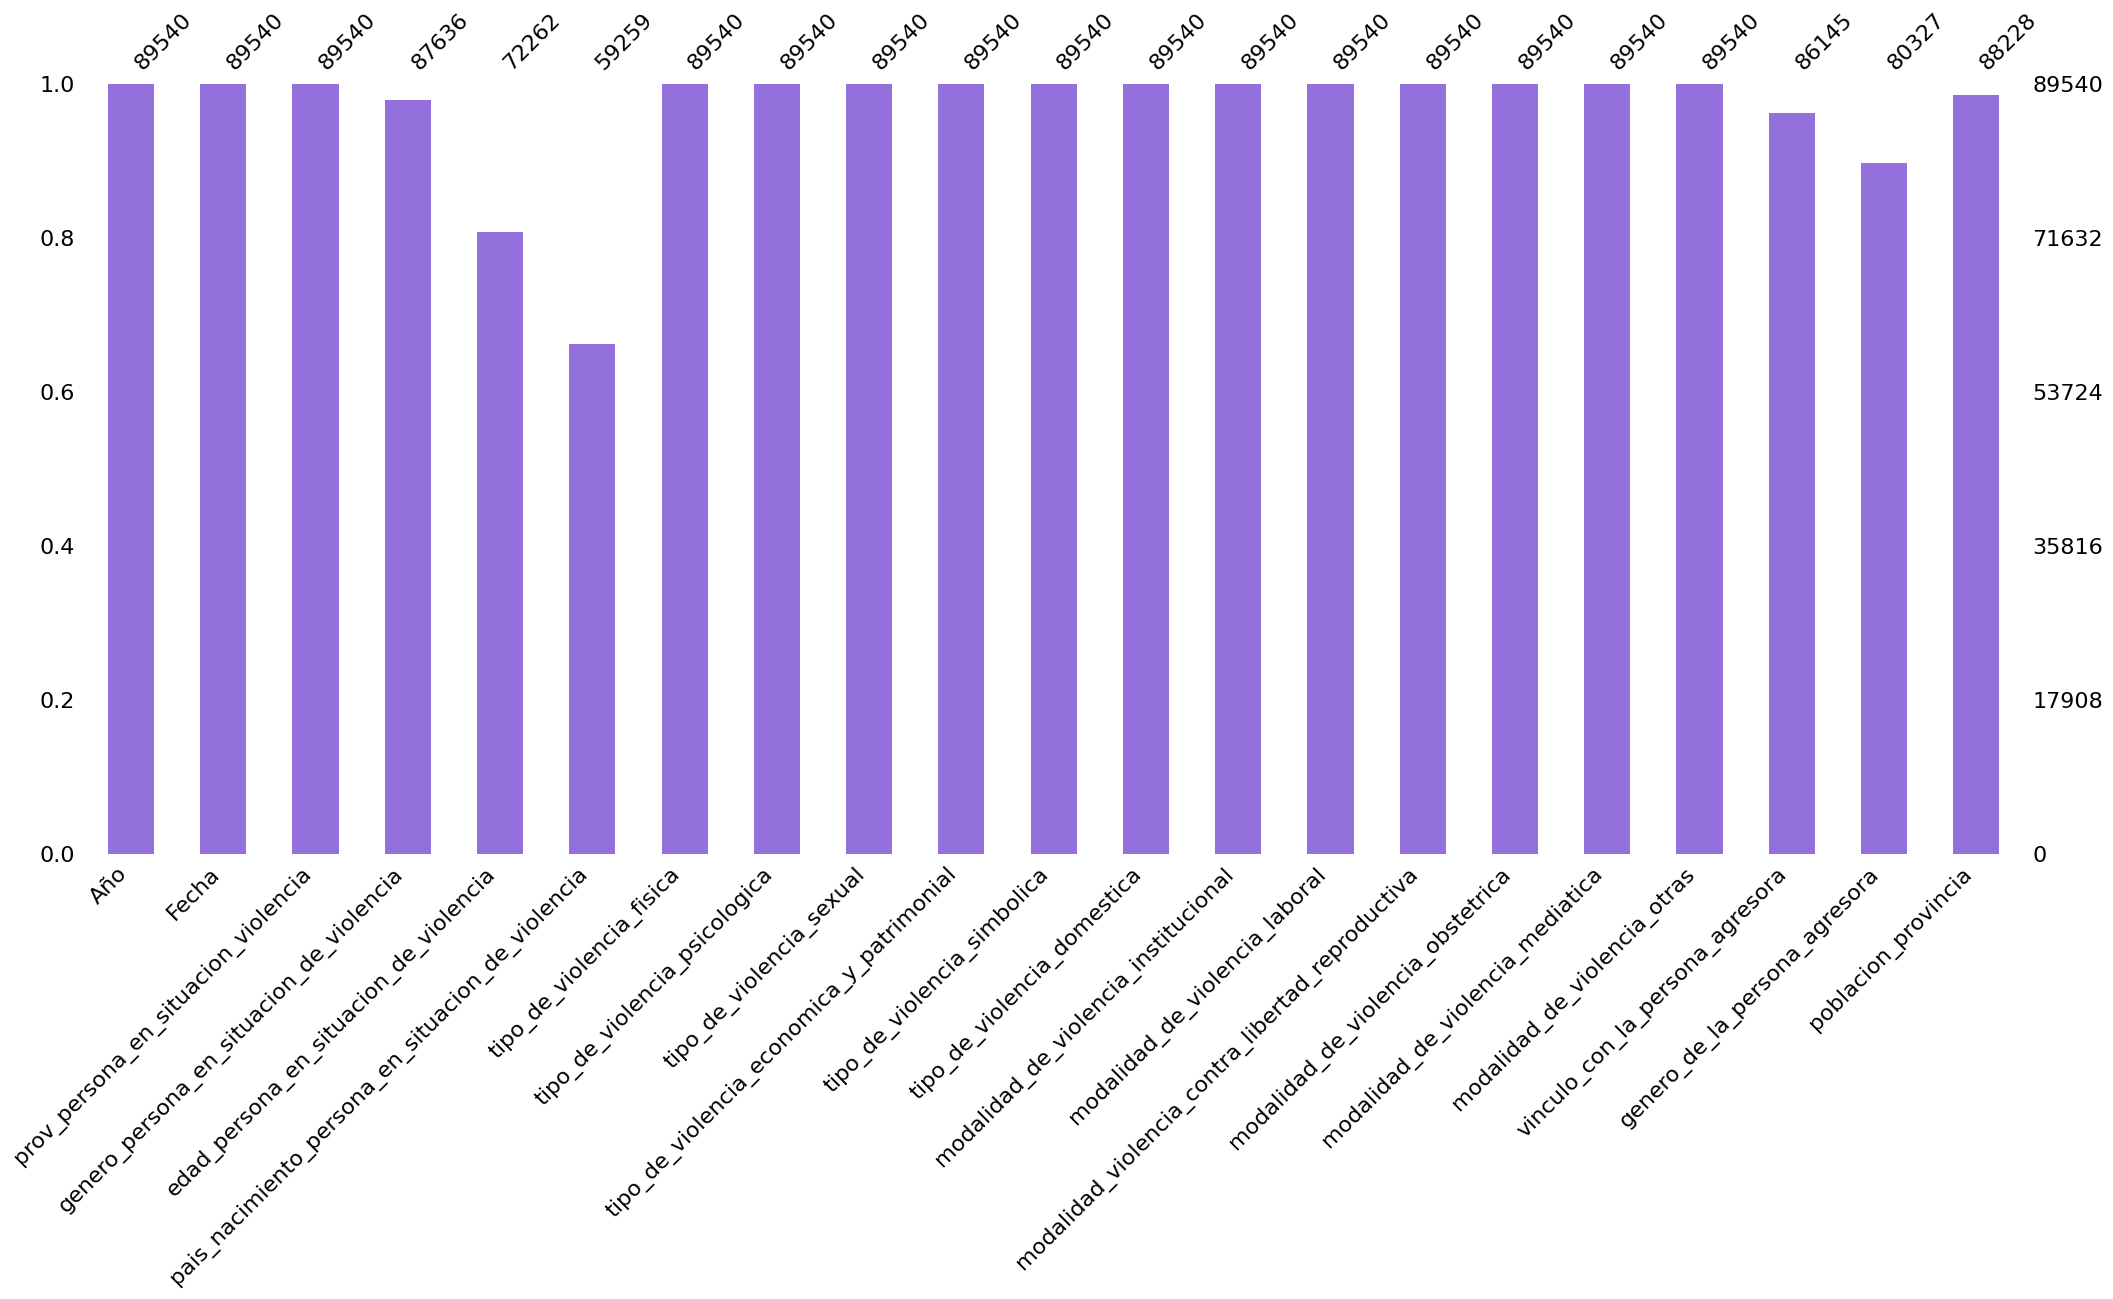

In [24]:
nulos_por_variable = df.isnull().sum()

print("Cantidad de valores nulos por variable:")
print(nulos_por_variable.sort_values(ascending=False))

msno.bar(df, color='mediumpurple')

En estas variables donde los registros no fueron anotados puede ser al ser censurados o no ser anotados o por error en el sistema, aun así la variable de `poblacion_provincia` fue debido a que esta relacionado o depende de otra variable, `prov_persona_en_situation_violencia`. Como hay 1287 con el valor `Sin datos`, y otro valor llamado `Sin Datos` con 25 registros, su suma da 1312, la misma cantidad que aparece en la busqueda reciente.

## Conclusión
- Se tratara los valores atípicos en la variable `edad_persona_en_situacion_de_violencia` debido a que existe un valor de 127 años de edad, pero los menores a 10 años permaneceran intactos debido a que la persona que hizo la llamada o reporto pudo haber sido otra.

- Se modificara el tipo de dato para `Fecha` a *datetime*, y será separados por día, mes y año.

- POBLACION TIPO DATO

- Se eliminara la variable año porque sino existira multiconolinealidad para `Año` y para las sub-variables de `Fecha`.

- Dentro de los `tipo de violencia` y `modalidad de violencia` serán normalizados los datos lógicos que tengan el mismo valor aunque estén escritos de distinta manera (ej: 'Si' y 'SI', aunque sean distintos datos dentro de las variables, su valor lógico es el mismo).

- Las restantes variables categóricas que tienen datos similares pero con el mismo valor también serán estandarizados para reducir el ruido

- Las variables donde tienen registro nulos, puede ser por MNAR, debido a que la persona al momento del reporte no quiso dar esa información, o aclaro que no quería ser publica esa información aunque no hubiera algo que la identificara, se realizara un análisis a profundidad a esos atributos.